In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

In [ ]:
load1 = pd.read_csv('I-80-Main-Data/Car_S1.csv', header=0)
load2 = pd.read_csv('I-80-Main-Data/Car_S2.csv', header=0)
load3 = pd.read_csv('I-80-Main-Data/Car_S3.csv', header=0)

df1 = pd.DataFrame(load1)
df2 = pd.DataFrame(load2)
df3 = pd.DataFrame(load3)
# Vertically concatenate the three datasets
all_data = pd.concat([df1, df2, df3], axis=0, ignore_index=True)
all_data['Acceleration_x'] = all_data['Acceleration_x'] * 10

In [10]:
class Segmentation():
    def __init__(self,all_data,desired_vehicle_id):
        self.all_data = all_data
        self.unique_vehicle_ids = all_data['VehicleID_x'].unique()
        self.desired_vehicle_id = desired_vehicle_id

    def cal_inflection_points(self,data):
        local_minima = argrelextrema(data, np.less)
        local_maxima = argrelextrema(data, np.greater)
        inflection_points = np.sort(np.concatenate((local_minima[0], local_maxima[0])))
        inflection_indexs = [i for i in inflection_points]
        inflection_indexs.insert(0,0)
        inflection_indexs.append(len(data)-1)
        inflection_coordinates = [data[i] for i in inflection_indexs]
        delta_x = np.diff(inflection_indexs)
        delta_y = np.diff(inflection_coordinates)
        delta_x = np.append(delta_x, 0)
        delta_y = np.append(delta_y, 0)

        return inflection_indexs, inflection_coordinates,delta_x,delta_y

    def generate_result_dataset(self,variables): #variables: Velocity_x, Acceleration_x, distance, delta_v
        results = []
        for vehicle_id in self.unique_vehicle_ids:
            vehicle_data = all_data[all_data['VehicleID_x'] == vehicle_id]
            time_id = vehicle_data['FrameID'].values
            speed = vehicle_data[str(variables)].values
            inflection_points, inflection_coordinates, delta_x, delta_y = self.cal_inflection_points(speed)
            inflection_time_ids = [time_id[i] for i in inflection_points]
            result_data = pd.DataFrame({
                'VehicleID': vehicle_id,
                'InflectionTimeID': inflection_time_ids,
                'InflectionSpeed': inflection_coordinates,
                'DeltaX': delta_x,
                'DeltaY': delta_y
            })
            results.append(result_data)
        result_dataset = pd.concat(results, ignore_index=True)
        return result_dataset

    def find_data(self,result_dataset):
        single_vehicle_result = result_dataset[result_dataset['VehicleID'] == self.desired_vehicle_id]
        single_vehicle_data = all_data[all_data['VehicleID_x'] == self.desired_vehicle_id]
        delta_t = single_vehicle_result['DeltaX'].values
        delta_y = single_vehicle_result['DeltaY'].values
        time_turning_points = single_vehicle_result['InflectionTimeID'].values
        turning_points_values = single_vehicle_result['InflectionSpeed'].values
        return single_vehicle_data,delta_t,delta_y,time_turning_points,turning_points_values

    def get_states_set(self,delta_y,theta1,theta2):
        states = []
        # try 1 st
        for dy in delta_y:
            if dy >= theta1:
                state = 'I'
            elif dy <= theta2:
                state = 'D'
            else:
                state = 'K'
            states.append(state)
        return states

    def merge(self,states,delta_t,delta_y,time_turning_points,theta1,theta2,gama):
        merged_index_set = []
        for index, j in enumerate(states):
            if index < 1:
                if states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            elif index == len(states)-1:
                if states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            else:
                if states[index-1] != j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index-1] == j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index+1] == j and states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index+1]
                        merged_index_set.append(index)
        try:
            merged_index_set.remove(0)
        except:
            pass
        try:
            merged_index_set.remove(len(time_turning_points)-1)
        except:
            pass
        time_turning_points_final = np.delete(time_turning_points, merged_index_set)

        return time_turning_points_final,merged_index_set

    def cal_states_final(self,states,variable,turning_point,merged_index_set):
        if str(variable) != 'Acceleration_x':
            variable_threshold = np.percentile(all_data[str(variable)], 50)
        else:
            variable_threshold = 0
        for index, point in enumerate(turning_point):
            if states[index] == 'K':
                if index != turning_point.shape[0]-1:
                    next_point = turning_point[index]
                else:
                    next_point = turning_point[-1]
                point -= turning_point[0]
                next_point -= turning_point[0]
                mean_variable = np.mean(single_vehicle_data[str(variable)][point:next_point+1])
                if mean_variable >= variable_threshold:
                    states[index] = 'H'
                else:
                    states[index] = 'L'
        states_final = [i for index,i in enumerate(states) if index not in merged_index_set]
        # print(states_final)
        return states_final

    def plt_segment(self,variable,y_label,single_vehicle_data,state_final,turning_point):
        # 创建速度曲线图
        plt.figure(figsize=(10, 5))
        x_min = min(single_vehicle_data['FrameID'])
        x_max = max(single_vehicle_data['FrameID'])
        plt.xlim(x_min, x_max)
        plt.plot(single_vehicle_data['FrameID'].values, single_vehicle_data[str(variable)].values, color = 'red', linestyle='-', linewidth=1)

        plt.xlabel('Time')
        plt.ylabel(str(y_label))
        plt.title('Segmentation')

        # 在转折点处添加垂直线和状态标签
        for i, state in enumerate(state_final):
            start = turning_point[i]
            if start == turning_point[-1]:
                end = turning_point[i]
            else:
                end = turning_point[i+1]
            x_pos = (start + end) / 2
            plt.axvline(x=start, color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=turning_point[-1], color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=0, color='grey', linestyle='--', alpha=0.5)
        COLOR = []
        cood = []
        # 在不同状态区间上添加不同颜色的填充
        for i in range(len(state_final)):
            start = turning_point[i]
            if i != len(state_final)-1:
                end = turning_point[i + 1]
            else:
                end = int(single_vehicle_data['FrameID'].values[-1])

            color = None
            if state_final[i] == 'I':
                color = 'red'
            elif state_final[i] == 'H':
                color = 'yellow'
            elif state_final[i] == 'L':
                color = 'green'
            elif state_final[i] == 'D':
                color = 'blue'
            COLOR.append(color)
            cood.append((start,end))
            plt.axvspan(start, end, color=color, alpha=0.4)
        plt.show()
        return

    def fill_color(self,velocity, acceleration, distance, delta_v, dataframe):
        COLOR_SET = [['#AED6F1', '#85C1E9', '#5DADE2', '#3498DB'],['#A9DFBF', '#82E0AA', '#58D68D', '#2ECC71'],['#F5B7B1', '#F1948A', '#EC7063', '#E74C3C'],['#D7BDE2', '#C39BD3', '#AF7AC5', '#9B59B6']]
        loc= [8,6,4,2]
        loc= [3.5,2.5,1.5,.5]

        fig,ax = plt.subplots(1,1,figsize=(20,1.5))
        plt.ylim(0,4)
        ax.yaxis.set_major_locator(plt.MultipleLocator(1))
        velocity_turning_points_final = dataframe['velocity_turning_points']
        velocity_states_final = dataframe['velocity_states']
        acceleration_turning_points_final =  dataframe['acceleration_turning_points']
        acceleration_states_final = dataframe['acceleration_states']
        distance_turning_points_final =  dataframe['distance_turning_points']
        distance_states_final = dataframe['distance_states']
        delta_v_turning_points_final =  dataframe['delta_v_turning_points']
        delta_v_states_final = dataframe['delta_v_states']
        if velocity:
            color_set = COLOR_SET[0]
            location = loc[0]
            for i in range(len(velocity_states_final)):
                if velocity_states_final[i] == 'I':
                    color = color_set[0]
                elif velocity_states_final[i] == 'H':
                    color = color_set[1]
                elif velocity_states_final[i] == 'L':
                    color = color_set[2]
                elif velocity_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(velocity_states_final)-1:
                    ax.fill_between([velocity_turning_points_final[i],velocity_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8)
        if acceleration:
            color_set = COLOR_SET[1]
            location = loc[1]
            for i in range(len(acceleration_states_final)):
                if acceleration_states_final[i] == 'I':
                    color = color_set[0]
                elif acceleration_states_final[i] == 'H':
                    color = color_set[1]
                elif acceleration_states_final[i] == 'L':
                    color = color_set[2]
                elif acceleration_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(acceleration_states_final)-1:
                    # print(color,'a')
                    ax.fill_between([acceleration_turning_points_final[i],acceleration_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8)
        if distance:
            color_set = COLOR_SET[2]
            location = loc[2]
            for i in range(len(distance_states_final)):
                if distance_states_final[i] == 'I':
                    color = color_set[0]
                elif distance_states_final[i] == 'H':
                    color = color_set[1]
                elif distance_states_final[i] == 'L':
                    color = color_set[2]
                elif distance_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(distance_states_final)-1:
                    # print(color,'d')
                    ax.fill_between([distance_turning_points_final[i],distance_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8)
        if delta_v:
            color_set = COLOR_SET[3]
            location = loc[3]
            for i in range(len(delta_v_states_final)):
                if delta_v_states_final[i] == 'I':
                    color = color_set[0]
                elif delta_v_states_final[i] == 'H':
                    color = color_set[1]
                elif delta_v_states_final[i] == 'L':
                    color = color_set[2]
                elif delta_v_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(delta_v_states_final)-1:
                    # print(color,'dv')
                    ax.fill_between([delta_v_turning_points_final[i],delta_v_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8)
        y_ticks_loc = [0.5,1.5,2.5,3.5]
        y_ticks = [r'$\Delta v$', r'$d$', r'$a$', r'$v$']
        ax.set_yticks(y_ticks_loc)
        ax.set_yticklabels(y_ticks)
        ax.grid(None)
        plt.xlim(velocity_turning_points_final[0],velocity_turning_points_final[-1])
        ax.set_xlabel('FrameID')
        ax.set_ylabel('Variables')
        ax.set_title('Driving behavior map (Example of ID245)')
        plt.show()
        return

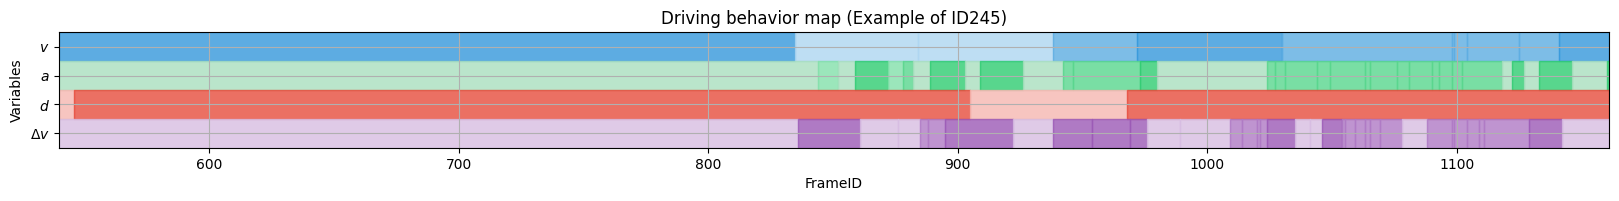

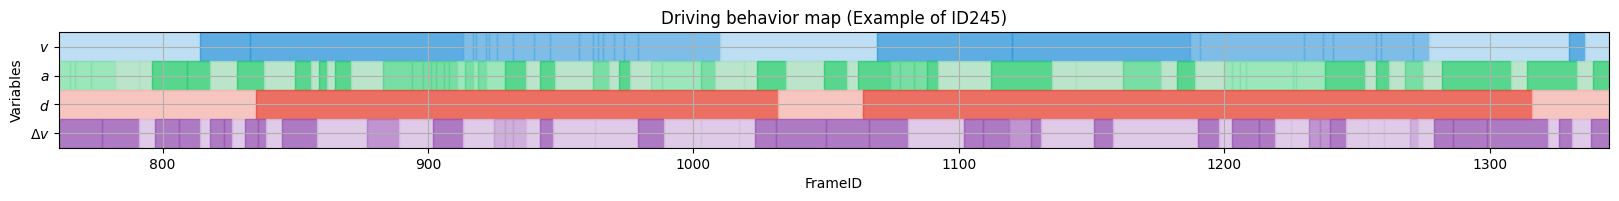

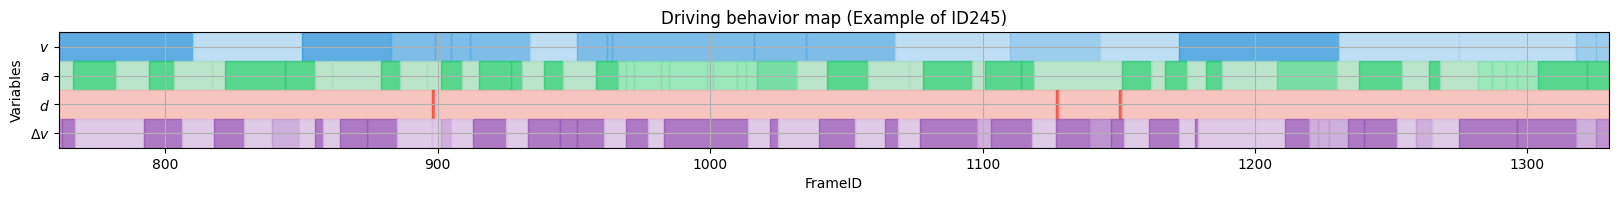

In [11]:
unique_vehicle_ids = all_data['VehicleID_x'].unique()
df = {}
all_vehicle_df ={}
for index, desired_vehicle_id in enumerate(unique_vehicle_ids):
    # desired_vehicle_id = 245
    sg = Segmentation(all_data,desired_vehicle_id)

    result_dataset_velocity = sg.generate_result_dataset('Velocity_x')
    result_dataset_acceleration = sg.generate_result_dataset('Acceleration_x')
    result_dataset_distance = sg.generate_result_dataset('distance')
    result_dataset_delta_v = sg.generate_result_dataset('delta_v')

    # theta1_velocity = np.percentile(result_dataset_velocity['DeltaY'], 75)
    # theta2_velocity = np.percentile(result_dataset_velocity['DeltaY'], 25)
    # theta1_acceleration = np.percentile(result_dataset_acceleration['DeltaY'], 75)
    # theta2_acceleration = np.percentile(result_dataset_acceleration['DeltaY'], 25)
    # theta1_distance = np.percentile(result_dataset_distance['DeltaY'], 75)
    # theta2_distance = np.percentile(result_dataset_distance['DeltaY'], 25)
    # theta1_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 75)
    # theta2_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 25)
    gama = 30
    theta1_velocity = 1
    theta2_velocity = -1
    theta1_acceleration = 0.5
    theta2_acceleration = - 0.5
    theta1_distance = np.percentile(result_dataset_distance['DeltaY'], 75)
    theta2_distance = np.percentile(result_dataset_distance['DeltaY'], 25)
    theta1_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 75)
    theta2_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 25)

    single_vehicle_data,delta_t_v,delta_y_v,time_turning_points_v,turning_points_values_v = sg.find_data(result_dataset_velocity)
    _,delta_t_a,delta_y_a,time_turning_points_a,turning_points_values_a = sg.find_data(result_dataset_acceleration)
    _,delta_t_d,delta_y_d,time_turning_points_d,turning_points_values_d = sg.find_data(result_dataset_distance)
    _,delta_t_dv,delta_y_dv,time_turning_points_dv,turning_points_values_dv = sg.find_data(result_dataset_delta_v)

    states_v = sg.get_states_set(delta_y_v,theta1_velocity,theta2_velocity)
    states_a = sg.get_states_set(delta_y_a,theta1_acceleration,theta2_acceleration)
    states_d = sg.get_states_set(delta_y_d,theta1_distance,theta2_distance)
    states_dv =sg.get_states_set(delta_y_dv,theta1_delta_v,theta2_delta_v)

    turning_points_final_v,merged_index_set_v = sg.merge(states_v,delta_t_v,delta_y_v,time_turning_points_v,theta1_velocity,theta2_velocity,gama)
    turning_points_final_a,merged_index_set_a = sg.merge(states_a,delta_t_a,delta_y_a,time_turning_points_a,theta1_acceleration,theta2_acceleration,gama)
    turning_points_final_d,merged_index_set_d = sg.merge(states_d,delta_t_d,delta_y_d,time_turning_points_d,theta1_distance,theta2_distance,gama)
    turning_points_final_dv,merged_index_set_dv = sg.merge(states_dv,delta_t_dv,delta_y_dv,time_turning_points_dv,theta1_delta_v,theta2_delta_v,gama)

    states_v_final = sg.cal_states_final(states_v,'Velocity_x',time_turning_points_v,merged_index_set_v)
    states_a_final = sg.cal_states_final(states_a,'Acceleration_x',time_turning_points_a,merged_index_set_a)
    states_d_final = sg.cal_states_final(states_d,'distance',time_turning_points_d,merged_index_set_d)
    states_dv_final = sg.cal_states_final(states_dv,'delta_v',time_turning_points_dv,merged_index_set_dv)

    df['velocity_turning_points'] = turning_points_final_v
    df['velocity_states'] = states_v_final
    df['acceleration_turning_points'] = turning_points_final_a
    df['acceleration_states'] = states_a_final
    df['distance_turning_points'] = turning_points_final_d
    df['distance_states'] = states_d_final
    df['delta_v_turning_points'] = turning_points_final_dv
    df['delta_v_states']= states_dv_final
    # print(df)
    all_vehicle_df['{0}'.format(desired_vehicle_id)]=df
    # sg.plt_segment('Velocity_x','Velocity',single_vehicle_data,states_v_final,turning_points_final_v)
    # sg.plt_segment('Acceleration_x','Acceleration',single_vehicle_data,states_a_final,turning_points_final_a)
    # sg.plt_segment('distance','Distance',single_vehicle_data,states_d_final,turning_points_final_d)
    # sg.plt_segment('delta_v','Delta_v',single_vehicle_data,states_dv_final,turning_points_final_dv)

    sg.fill_color(1,1,1,1,dataframe = df)

    if index > 1:
        break